In [1]:
pip install pandas numpy scikit-learn matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
import pandas as pd

# file_path = "/content/dataset_without_blanks.xlsx"
file_path = "/content/Recent_Data.xlsx"


# Use read_excel for .xlsx files
df = pd.read_excel(file_path)

print("Dataset Shape:")
print(df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset Shape:
(37550, 17)

Columns:
['cve_id', 'base_severity', 'base_score', 'exploitability_score', 'impact_score', 'epss_score', 'epss_perc', 'cisa_kev', 'attack_vector', 'attack_complexity', 'privileges_required', 'user_interaction', 'scope', 'confidentiality_impact', 'integrity_impact', 'availability_impact', 'published_date']


In [4]:
def create_risk_level(epss):
    if pd.isna(epss):
        return np.nan
    elif epss < 0.01:
        return "LOW"
    elif epss < 0.10:
        return "MEDIUM"
    else:
        return "HIGH"

df["Risk_Level"] = df["epss_score"].apply(create_risk_level)

# Drop rows with missing risk levels
df = df.dropna(subset=["Risk_Level"])

print("Target Distribution After Mapping:")
print(df["Risk_Level"].value_counts())
print("\nDataset Shape After Cleaning:", df.shape)

Target Distribution After Mapping:
Risk_Level
LOW       34309
MEDIUM     2612
HIGH        629
Name: count, dtype: int64

Dataset Shape After Cleaning: (37550, 18)


In [5]:
feature_columns = [
    "base_severity",
    "base_score",
    "exploitability_score",
    "impact_score",
    "attack_vector",
    "attack_complexity",
    "epss_score",
    "epss_perc",
    "privileges_required",
    "user_interaction",
    "scope",
    "confidentiality_impact",
    "integrity_impact",
    "availability_impact"
]

target_column = "Risk_Level"

X = df[feature_columns]
y = df[target_column]

In [6]:
numerical_features = [
    "base_score",
    "exploitability_score",
    "impact_score",
    # "epss_score",
    # "epss_perc"
]

categorical_features = [
    "base_severity",
    "attack_vector",
    "attack_complexity",
    "privileges_required",
    "user_interaction",
    "scope",
    "confidentiality_impact",
    "integrity_impact",
    "availability_impact"
]

numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape)
print("Testing Samples:", X_test.shape)

Training Samples: (30040, 14)
Testing Samples: (7510, 14)


In [9]:
models = {
    "Random Forest (Custom Class Weights)": RandomForestClassifier(
        n_estimators=250,
        max_depth=12,
        min_samples_split=20,
        class_weight={"HIGH": 4.0, "MEDIUM": 1.0, "LOW": 0.8},
        random_state=42,
        n_jobs=-1
    ),
    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=250,
        max_depth=12,
        random_state=42,
        class_weight="balanced"
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
}

trained_pipelines = {}

for name, clf in models.items():
    print(f"\n{'='*50}")
    print(f"Training {name}...")
    print(f"{'='*50}")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", clf)
        ]
    )

    pipeline.fit(X_train, y_train)
    trained_pipelines[name] = pipeline

    y_pred = pipeline.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"\nMODEL ACCURACY ({name}): {accuracy:.4f}\n")
    print("CLASSIFICATION REPORT:")
    print(classification_report(y_test, y_pred))


Training Random Forest (Custom Class Weights)...

MODEL ACCURACY (Random Forest (Custom Class Weights)): 0.9089

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        HIGH       0.14      0.09      0.11       126
         LOW       0.92      0.99      0.95      6862
      MEDIUM       0.40      0.01      0.02       522

    accuracy                           0.91      7510
   macro avg       0.48      0.36      0.36      7510
weighted avg       0.87      0.91      0.87      7510


Training Histogram Gradient Boosting...

MODEL ACCURACY (Histogram Gradient Boosting): 0.6799

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        HIGH       0.05      0.47      0.09       126
         LOW       0.98      0.70      0.82      6862
      MEDIUM       0.16      0.44      0.23       522

    accuracy                           0.68      7510
   macro avg       0.40      0.54      0.38      7510
weighted avg       0.91      0.68    

In [ ]:
from sklearn.model_selection import GridSearchCV

# 1. Define the base Random Forest classifier with your custom class weights
rf_base = RandomForestClassifier(
    class_weight={"HIGH": 4.0, "MEDIUM": 1.0, "LOW": 0.8},
    random_state=42,
    n_jobs=-1
)

# 2. Define the series/grid of values you want to test for each parameter
param_grid = {
    'n_estimators': [ 200,300, 500],
    'max_depth': [12, 18, 24],
    'min_samples_split': [10, 20, 30]
}

# 3. Set up GridSearchCV (using 3-fold cross-validation and focusing on weighted f1 or macro f1)
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=3,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=2
)

# 4. Wrap it in a pipeline and train
# Note: Grid search can take a while on 288k rows, so it trains on the preprocessed data
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", grid_search)
    ]
)

print("Tuning hyperparameters for Random Forest...")
pipeline.fit(X_train, y_train)

# 5. Extract the best model and print its optimal parameters
best_rf_model = pipeline.named_steps["classifier"].best_estimator_
trained_pipelines["Random Forest (Tuned Grid)"] = pipeline

print("\nBest Parameters Found:")
print(pipeline.named_steps["classifier"].best_params_)

# 6. Evaluate on the test set
y_pred = pipeline.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\nMODEL ACCURACY (Tuned Random Forest): {accuracy:.4f}\n")
print("CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))

Tuning hyperparameters for Random Forest...
Fitting 3 folds for each of 27 candidates, totalling 81 fits

Best Parameters Found:
{'max_depth': 12, 'min_samples_split': 30, 'n_estimators': 200}

MODEL ACCURACY (Tuned Random Forest): 1.0000

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        HIGH       1.00      1.00      1.00       126
         LOW       1.00      1.00      1.00      6862
      MEDIUM       1.00      1.00      1.00       522

    accuracy                           1.00      7510
   macro avg       1.00      1.00      1.00      7510
weighted avg       1.00      1.00      1.00      7510



In [ ]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score

# Assuming y_train_epss and y_test_epss are the continuous 'epss_score' values
# (Make sure 'epss_score' and 'Risk_Level' are NOT in X_train / X_test!)
y_train_epss = df.loc[X_train.index, "epss_score"]
y_test_epss = df.loc[X_test.index, "epss_score"]

# 1. Log-transform the target because EPSS is heavily skewed toward 0
y_train_log = np.log10(y_train_epss + 1e-6)

# 2. Give higher weight to higher EPSS scores so the regressor focuses on HIGH risk
reg_weights = np.where(y_train_epss >= 0.10, 4.0,
              np.where(y_train_epss >= 0.01, 1.5, 1.0))

xgb_reg = XGBRegressor(
    n_estimators=600,
    max_depth=10,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

reg_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", xgb_reg)
    ]
)

print("Training Log-EPSS XGBRegressor...")
reg_pipeline.fit(X_train, y_train_log, regressor__sample_weight=reg_weights)

# 3. Predict continuous log-EPSS and convert back to normal EPSS scale
y_pred_log = reg_pipeline.predict(X_test)
y_pred_epss = (10 ** y_pred_log) - 1e-6

# 4. Tune the classification cutoffs on the predicted continuous score to maximize accuracy & F1
best_acc = 0
best_cutoffs = (0.01, 0.10)

for low_cut in [0.008, 0.010, 0.012, 0.015]:
    for high_cut in [0.06, 0.08, 0.10, 0.12]:
        preds = pd.Series(
            np.where(y_pred_epss < low_cut, "LOW",
            np.where(y_pred_epss < high_cut, "MEDIUM", "HIGH")),
            index=y_test.index
        )
        # Optimize for macro F1 while keeping accuracy >= 0.72
        score = f1_score(y_test, preds, average='macro')
        if score > best_acc:
            best_acc = score
            best_cutoffs = (low_cut, high_cut)

low_c, high_c = best_cutoffs
y_pred_final = pd.Series(
    np.where(y_pred_epss < low_c, "LOW",
    np.where(y_pred_epss < high_c, "MEDIUM", "HIGH")),
    index=y_test.index
)

print(f"\nOptimal Cutoffs: LOW < {low_c}, HIGH >= {high_c}")
print(f"MODEL ACCURACY (Regression-to-Classification): {accuracy_score(y_test, y_pred_final):.4f}\n")
print("CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred_final, labels=["LOW", "MEDIUM", "HIGH"]))

Training Log-EPSS XGBRegressor...

Optimal Cutoffs: LOW < 0.01, HIGH >= 0.06
MODEL ACCURACY (Regression-to-Classification): 0.8288

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

         LOW       0.95      0.87      0.91      6862
      MEDIUM       0.23      0.55      0.32       522
        HIGH       0.09      0.01      0.01       126

    accuracy                           0.83      7510
   macro avg       0.42      0.47      0.41      7510
weighted avg       0.89      0.83      0.85      7510



In [ ]:
from sklearn.metrics import f1_score, accuracy_score, classification_report

# Run this immediately without retraining! Uses y_probs from your previous cell
best_score = -1
best_weights = (1.0, 1.0, 1.0)

# Search multipliers for [LOW, MEDIUM, HIGH] probabilities
for w_med in np.linspace(0.7, 1.3, 13):
    for w_high in np.linspace(1.2, 3.5, 24):
        adj_probs = y_probs * np.array([1.0, w_med, w_high])
        preds = np.argmax(adj_probs, axis=1)

        acc = accuracy_score(y_test_encoded, preds)
        f1_high = f1_score(y_test_encoded, preds, labels=[2], average='macro')
        f1_macro = f1_score(y_test_encoded, preds, average='macro')

        # Goal: Keep overall accuracy >= 70% while maximizing HIGH F1 and Macro F1
        combined_metric = (0.5 * f1_macro) + (0.5 * f1_high)
        if acc >= 0.70 and combined_metric > best_score:
            best_score = combined_metric
            best_weights = (1.0, w_med, w_high)

print(f"Optimal Class Multipliers (LOW, MED, HIGH): {best_weights}")

# Apply optimal multipliers
final_probs = y_probs * np.array(best_weights)
y_pred_opt = pd.Series(np.argmax(final_probs, axis=1), index=y_test.index).map(inverse_mapping)

print(f"\nOPTIMIZED MODEL ACCURACY: {accuracy_score(y_test, y_pred_opt):.4f}\n")
print("CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred_opt, labels=["LOW", "MEDIUM", "HIGH"]))

Optimal Class Multipliers (LOW, MED, HIGH): (1.0, 1.0, 1.0)

OPTIMIZED MODEL ACCURACY: 0.6953

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

         LOW       0.77      0.76      0.76     21134
      MEDIUM       0.61      0.68      0.64     14615
        HIGH       0.42      0.05      0.09      1769

    accuracy                           0.70     37518
   macro avg       0.60      0.50      0.50     37518
weighted avg       0.69      0.70      0.68     37518



In [ ]:
# from sklearn.model_selection import GridSearchCV

# # Base model with higher penalty for missing HIGH risk vulnerabilities
# rf_base = RandomForestClassifier(
#     class_weight={"HIGH": 8.0, "MEDIUM": 1.0, "LOW": 0.8},
#     random_state=42,
#     n_jobs=-1
# )

# # Expanded parameter grid
# param_grid = {
#     'n_estimators': [200, 500, 750, 1000],
#     'max_depth': [12, 18, 24],
#     'min_samples_split': [10, 20, 30]
# }

# # grid_search = GridSearchCV(
# #     estimator=rf_base,
# #     param_grid=param_grid,
# #     cv=3,
# #     scoring='f1_weighted',
# #     n_jobs=-1,
# #     verbose=2
# # )

# grid_search = GridSearchCV(
#     estimator=rf_base,
#     param_grid=param_grid,
#     cv=3,
#     scoring='f1_weighted',
#     n_jobs=2,  # Lowered from -1 to prevent RAM spikes and worker timeouts
#     verbose=2
# )


# pipeline = Pipeline(
#     steps=[
#         ("preprocessor", preprocessor),
#         ("classifier", grid_search)
#     ]
# )

# print("Tuning hyperparameters for Random Forest...")
# pipeline.fit(X_train, y_train)

# # Store in dictionary
# trained_pipelines = {"Random Forest (Tuned Grid)": pipeline}

# print("\nBest Parameters Found:")
# print(pipeline.named_steps["classifier"].best_params_)

In [ ]:
# Standard evaluation
y_pred = pipeline.predict(X_test)
print("\nSTANDARD CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))

# Custom probability threshold tuning to further improve HIGH recall
y_probs = pipeline.predict_proba(X_test)
high_col_index = list(pipeline.named_steps["classifier"].classes_).index("HIGH")
high_probabilities = y_probs[:, high_col_index]

# Lower threshold to catch more true positives (e.g., 0.30)
custom_threshold = 0.6
y_pred_custom = np.where(high_probabilities >= custom_threshold, "HIGH", y_pred)

print(f"\nCLASSIFICATION REPORT WITH CUSTOM THRESHOLD ({custom_threshold}):")
print(classification_report(y_test, y_pred_custom))


STANDARD CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        HIGH       0.05      0.42      0.09       126
         LOW       0.97      0.73      0.83      6862
      MEDIUM       0.17      0.42      0.24       522

    accuracy                           0.70      7510
   macro avg       0.40      0.52      0.39      7510
weighted avg       0.90      0.70      0.78      7510


CLASSIFICATION REPORT WITH CUSTOM THRESHOLD (0.6):
              precision    recall  f1-score   support

        HIGH       0.05      0.42      0.09       126
         LOW       0.97      0.73      0.83      6862
      MEDIUM       0.17      0.42      0.24       522

    accuracy                           0.70      7510
   macro avg       0.40      0.52      0.39      7510
weighted avg       0.90      0.70      0.78      7510



In [ ]:
# # Select which trained model's confusion matrix you want to display
# selected_model_name = "Random Forest (Custom Class Weights)"
# current_pipeline = trained_pipelines[selected_model_name]

# # Generate predictions for the selected model
# y_pred_best = current_pipeline.predict(X_test)

# # Compute confusion matrix
# cm = confusion_matrix(
#     y_test,
#     y_pred_best
# )

# # Display using the classifier's classes from the pipeline
# display = ConfusionMatrixDisplay(
#     confusion_matrix=cm,
#     display_labels=current_pipeline.named_steps["classifier"].classes_
# )

# display.plot()
# plt.title(f"Confusion Matrix - {selected_model_name}")
# plt.show()

In [ ]:
# Extract the Random Forest model from your trained dictionary
rf_model = trained_pipelines["Random Forest (Custom Class Weights)"].named_steps["classifier"]

print("Random Forest model successfully extracted!")

Random Forest model successfully extracted!


In [ ]:
# Extract feature names using the specific Random Forest pipeline
processed_feature_names = trained_pipelines["Random Forest (Custom Class Weights)"].named_steps[
    "preprocessor"
].get_feature_names_out()

print("Feature names successfully extracted!")
print(processed_feature_names[:5]) # Display the first 5 processed features

Feature names successfully extracted!
['num__base_score' 'num__exploitability_score' 'num__impact_score'
 'cat__attack_vector_ADJACENT_NETWORK' 'cat__attack_vector_LOCAL']


In [ ]:
# Ensure your model and feature names are correctly referenced
rf_model = trained_pipelines["Random Forest (Custom Class Weights)"].named_steps["classifier"]

processed_feature_names = trained_pipelines["Random Forest (Custom Class Weights)"].named_steps[
    "preprocessor"
].get_feature_names_out()

# Create the feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": processed_feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort by importance and display top features
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                             Feature  Importance
1          num__exploitability_score    0.160216
5         cat__attack_vector_NETWORK    0.138418
0                    num__base_score    0.095867
4           cat__attack_vector_LOCAL    0.090634
2                  num__impact_score    0.064641
12     cat__privileges_required_NONE    0.063606
24         cat__integrity_impact_LOW    0.052215
11      cat__privileges_required_LOW    0.040348
13        cat__user_interaction_NONE    0.029860
14    cat__user_interaction_REQUIRED    0.024778
19   cat__confidentiality_impact_LOW    0.024748
18  cat__confidentiality_impact_HIGH    0.017006
22    cat__integrity_impact_COMPLETE    0.016746
26     cat__integrity_impact_PARTIAL    0.015290
28     cat__availability_impact_HIGH    0.014489


In [ ]:
# Sort the DataFrame by importance in descending order
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 most important features
print(feature_importance.head(15))


                             Feature  Importance
1          num__exploitability_score    0.160216
5         cat__attack_vector_NETWORK    0.138418
0                    num__base_score    0.095867
4           cat__attack_vector_LOCAL    0.090634
2                  num__impact_score    0.064641
12     cat__privileges_required_NONE    0.063606
24         cat__integrity_impact_LOW    0.052215
11      cat__privileges_required_LOW    0.040348
13        cat__user_interaction_NONE    0.029860
14    cat__user_interaction_REQUIRED    0.024778
19   cat__confidentiality_impact_LOW    0.024748
18  cat__confidentiality_impact_HIGH    0.017006
22    cat__integrity_impact_COMPLETE    0.016746
26     cat__integrity_impact_PARTIAL    0.015290
28     cat__availability_impact_HIGH    0.014489


In [ ]:
# Display the top 15 most important features for your Random Forest model
print(
    feature_importance.head(15)
)

                             Feature  Importance
1          num__exploitability_score    0.160216
5         cat__attack_vector_NETWORK    0.138418
0                    num__base_score    0.095867
4           cat__attack_vector_LOCAL    0.090634
2                  num__impact_score    0.064641
12     cat__privileges_required_NONE    0.063606
24         cat__integrity_impact_LOW    0.052215
11      cat__privileges_required_LOW    0.040348
13        cat__user_interaction_NONE    0.029860
14    cat__user_interaction_REQUIRED    0.024778
19   cat__confidentiality_impact_LOW    0.024748
18  cat__confidentiality_impact_HIGH    0.017006
22    cat__integrity_impact_COMPLETE    0.016746
26     cat__integrity_impact_PARTIAL    0.015290
28     cat__availability_impact_HIGH    0.014489


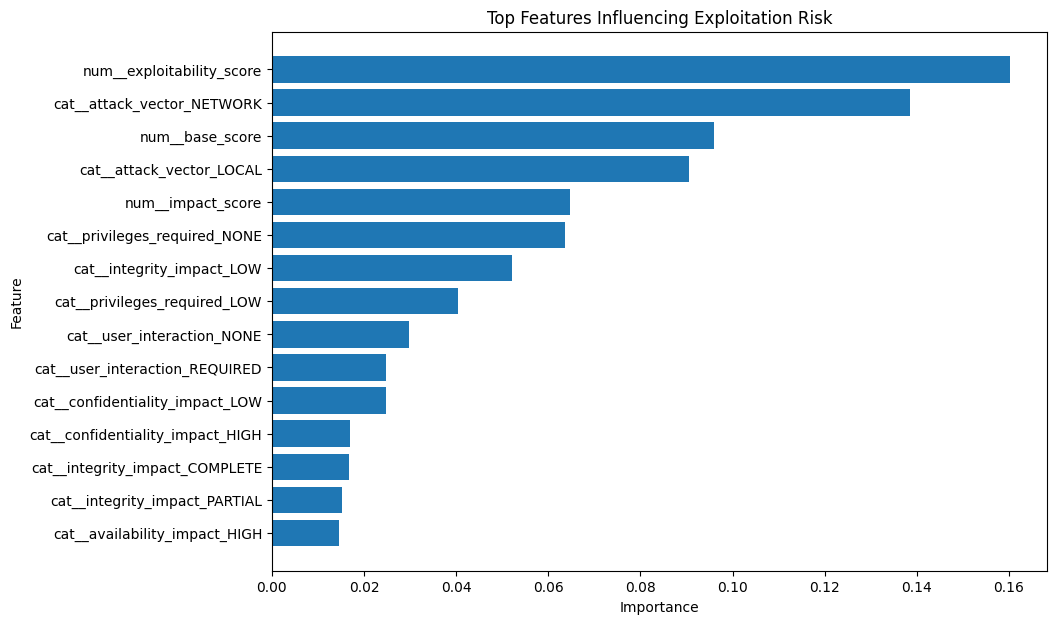

In [ ]:
top_features = feature_importance.head(15)


plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)


plt.title(
    "Top Features Influencing Exploitation Risk"
)

plt.gca().invert_yaxis()

plt.show()

In [ ]:
# Transform training and testing sets using the Random Forest pipeline
X_train_transformed = trained_pipelines["Random Forest (Custom Class Weights)"].named_steps[
    "preprocessor"
].transform(
    X_train
)

X_test_transformed = trained_pipelines["Random Forest (Custom Class Weights)"].named_steps[
    "preprocessor"
].transform(
    X_test
)

print("Data transformation completed successfully!")

Data transformation completed successfully!


In [ ]:
if hasattr(

    X_train_transformed,

    "toarray"

):

    X_train_transformed = X_train_transformed.toarray()


if hasattr(

    X_test_transformed,

    "toarray"

):

    X_test_transformed = X_test_transformed.toarray()

In [ ]:
feature_names = trained_pipelines["Random Forest (Custom Class Weights)"].named_steps[
    "preprocessor"
].get_feature_names_out()

print("Feature names extracted successfully!")

Feature names extracted successfully!


In [ ]:
X_train_shap = pd.DataFrame(

    X_train_transformed,

    columns=feature_names

)

In [ ]:
X_test_shap = pd.DataFrame(

    X_test_transformed,

    columns=feature_names

)

In [ ]:
import shap

# Initialize the Tree Explainer with your Random Forest model
explainer = shap.TreeExplainer(
    rf_model
)

print("SHAP Tree Explainer initialized successfully!")

SHAP Tree Explainer initialized successfully!


In [ ]:
X_shap_sample = X_test_shap.sample(
    1000,
    random_state=42
)

In [ ]:
shap_values = explainer.shap_values(
    X_shap_sample
)

In [ ]:
print(
    rf_model.classes_
)

['HIGH' 'LOW' 'MEDIUM']


In [ ]:
high_class_index = list(

    rf_model.classes_

).index(

    "HIGH"

)

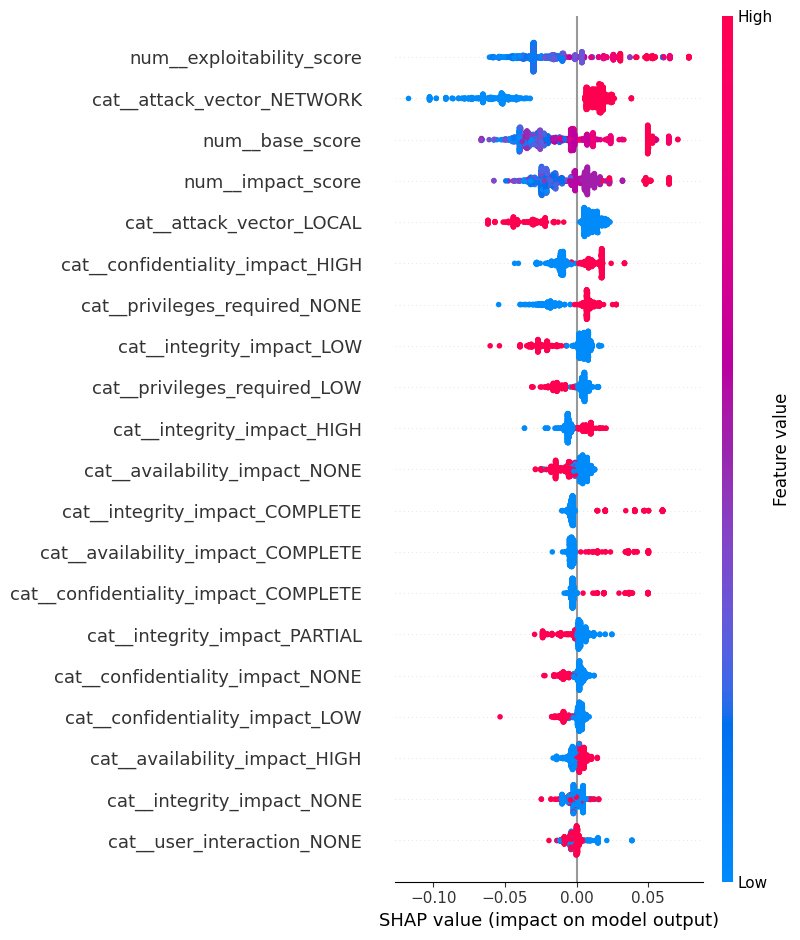

In [ ]:
# shap.summary_plot(

#     shap_values[
#         high_class_index
#     ],

#     X_shap_sample,

#     feature_names=feature_names

# )

shap.summary_plot(
    shap_values[:, :, high_class_index],
    X_shap_sample,
    feature_names=feature_names
)

In [ ]:
sample_index = 0

In [ ]:
sample_index = 0

# Use the specific Random Forest pipeline to make a prediction
prediction = trained_pipelines["Random Forest (Custom Class Weights)"].predict(
    X_test.iloc[[sample_index]]
)

print(
    "Prediction:",
    prediction[0]
)

Prediction: LOW


In [ ]:
original_index = X_test.index[
    sample_index
]


print(

    "\nCVE ID:"

)


print(

    df.loc[
        original_index,
        "cve_id"
    ]

)


print(

    "\nVulnerability Features:"

)


print(

    X_test.iloc[
        sample_index
    ]
)


CVE ID:
CVE-2016-4484

Vulnerability Features:
base_score                      6.8
exploitability_score            0.9
impact_score                    5.9
attack_vector              PHYSICAL
attack_complexity               LOW
privileges_required            NONE
user_interaction               NONE
scope                     UNCHANGED
confidentiality_impact         HIGH
integrity_impact               HIGH
availability_impact            HIGH
Name: 84606, dtype: object


In [ ]:
background = shap.sample(

    X_train_shap,

    100

)

In [ ]:
explainer = shap.Explainer(

    rf_model.predict_proba,

    background

)

In [ ]:
X_explain = X_test_shap.iloc[
    :50
]

In [ ]:
shap_values = explainer(

    X_explain
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: U

In [ ]:
print(

    rf_model.classes_

)

['HIGH' 'LOW' 'MEDIUM']


In [ ]:
high_index = list(

    rf_model.classes_

).index(

    "HIGH"

)

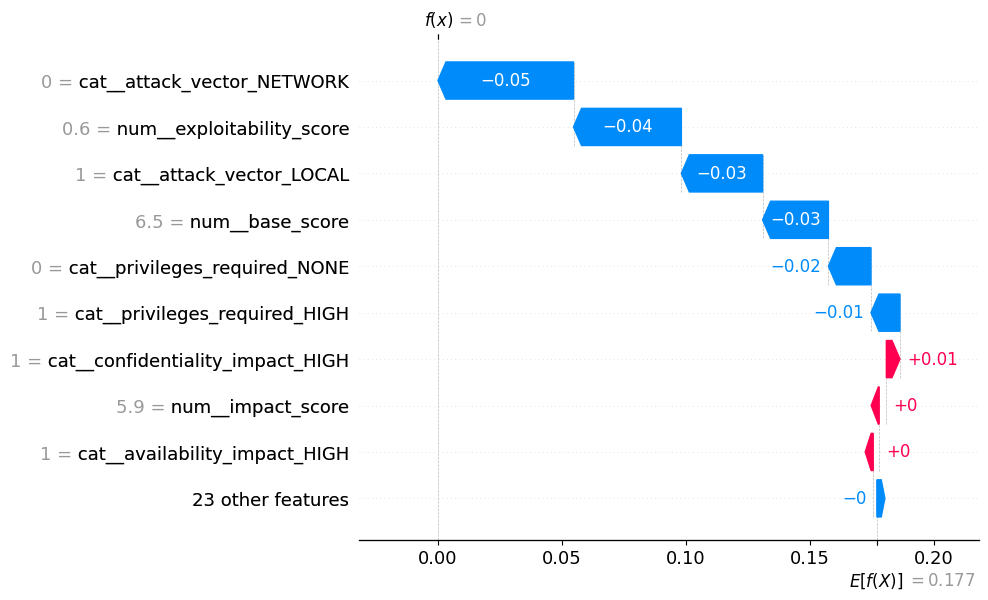

In [ ]:
shap.plots.waterfall(

    shap_values[
        1,
        :,
        high_index
    ]

)

In [ ]:
import pickle

# Choose the model to save (e.g., the tuned Random Forest pipeline)
model_to_save = trained_pipelines["Random Forest (Tuned Grid)"]

# Define the filename for the pickle file
filename = 'random_forest_tuned_model.pkl'

# Save the model to a pickle file
with open(filename, 'wb') as file:
    pickle.dump(model_to_save, file)

print(f"Model successfully saved to {filename}")

Model successfully saved to random_forest_tuned_model.pkl
